# E-01 — Exploratory analysis of arraignment decisions

**Question.** Which charge and record variables are most associated with a decision to set bail or remand, and what should the modeling team examine next?

**Scope.** NYC main-sample dockets from the training years only. `y_detain = 1` means **bail set or remanded at arraignment**, not actual detention. All rates are descriptive associations. This notebook does not read validation or test outcomes and does not make causal or discrimination claims.

**Outputs.** Aggregate tables below and deck-ready figures in `reports/figures/`. Levels smaller than `config.MIN_GROUP_N` are omitted; rates are also suppressed when either outcome count is below that threshold. No case-level rows or judge names are displayed.

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

from src import config

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "savefig.dpi": 180,
})
NAVY, TEAL, RUST, GRID = "#1E5367", "#447D6D", "#A85D35", "#E2E6E8"
SOURCE = ("Source: NY UCS Pretrial Release Data, "
          f"{min(config.TRAIN_YEARS)}–{max(config.TRAIN_YEARS)} NYC arraignments")
config.FIGURES.mkdir(parents=True, exist_ok=True)

## 1. Load only the training partition

The Parquet filter prevents validation or test rows from entering the notebook. The main-sample flag then applies the agreed sample rules. The list below contains only the columns needed for this EDA; the bail-made field is used solely in a descriptive calculation.

In [2]:
cols = list(dict.fromkeys([
    config.SPLIT_COL, config.MAIN_SAMPLE_COL, config.YEAR_COL, config.TARGET_Q1,
    config.RELEASE_COL, *config.FEATURES_CASE, "top_severity_at_arraign", "top_charge_weight_at_arraign",
    "top_charge_at_arraign_violent_felony_ind", "arraign_charge_category",
    "prior_vfo_cnt", "prior_nonvfo_cnt", "prior_misd_cnt",
    "pend_vfo", "pend_nonvfo", "pend_misd", "supervision",
    "dat_wo_ws_prior_to_arraign", "age_group", "gender", "arrest_type",
    "race", "bail_made_indicator", "judge_id", "county_name",
]))
data = pd.read_parquet(
    config.ANALYTIC_FILE, columns=cols,
    filters=[(config.SPLIT_COL, "==", "train")],
)
assert data[config.SPLIT_COL].eq("train").all()
assert set(data[config.YEAR_COL].dropna().astype(int)) <= set(config.TRAIN_YEARS)
data = data.loc[data[config.MAIN_SAMPLE_COL]].copy()
assert not data.empty and data[config.TARGET_Q1].notna().all()
print(f"Training main sample: {len(data):,} dockets; years: {sorted(data[config.YEAR_COL].unique())}")

Training main sample: 193,196 dockets; years: [np.int64(2021), np.int64(2022)]


## 2. Value audit before grouping

Review the observed levels against the UCS dictionary and the project handoff. The displayed audit suppresses rare levels; it is an aggregate view, never individual records. Missing DCJS values remain a separate category rather than zero prior history.

In [3]:
audit_cols = [
    config.RELEASE_COL, "top_severity_at_arraign", "top_charge_weight_at_arraign",
    "top_charge_at_arraign_violent_felony_ind", "arraign_charge_category",
    "race", "gender", "arrest_type", "bail_made_indicator",
]
audit_rows = []
for col in audit_cols:
    counts = data[col].astype("string").fillna("Missing").value_counts(dropna=False)
    for level, n in counts.items():
        if n >= config.MIN_GROUP_N:
            audit_rows.append({"variable": col, "level": level, "n": int(n)})
audit = pd.DataFrame(audit_rows)
display(audit)

,variable,level,n
0,release_decision_at_arraign,ROR,132274
1,release_decision_at_arraign,Nonmonetary release,35943
2,release_decision_at_arraign,Bail-set,23077
3,release_decision_at_arraign,Remanded,1902
4,top_severity_at_arraign,Misdemeanor,134180
5,top_severity_at_arraign,Felony,59016
6,top_charge_weight_at_arraign,AM,119732
7,top_charge_weight_at_arraign,DF,20432
8,top_charge_weight_at_arraign,CF,14555
9,top_charge_weight_at_arraign,BF,12063


## 3. Feature landscape: completeness, concentration, and distributions

This section profiles **all 18 `CASE` inputs**, before looking at their relationship with the decision. The exported tables contain aggregates only. For the count fields, zero shares and quantiles use nonmissing values; the source caps several prior counts. `top_arraign_attempt_indicator` is blank for non-attempts, so its large blank share is a *coded category*, not a general data-loss rate. Missing DCJS history remains distinct from zero.

In [4]:
from src.features import NUMERIC

inventory_rows = []
level_rows = []
for feature in config.FEATURES_CASE:
    series = data[feature]
    observed = series.notna()
    item = {
        "feature": feature,
        "type": "numeric" if feature in NUMERIC else "categorical",
        "missing_n": int((~observed).sum()),
        "missing_pct": float((~observed).mean() * 100),
        "n_levels_observed": int(series.nunique(dropna=True)),
    }
    if feature in NUMERIC:
        numeric = pd.to_numeric(series, errors="coerce")
        item.update({
            "zero_pct_observed": float(numeric.loc[observed].eq(0).mean() * 100),
            "median": float(numeric.median()),
            "p90": float(numeric.quantile(.9)),
            "p99": float(numeric.quantile(.99)),
            "observed_max": float(numeric.max()),
        })
        if feature != "age_at_arrest":
            level_series = numeric.astype("Int64").astype("string").fillna("DCJS missing")
        else:
            level_series = data["age_group"].astype("string").fillna("Missing")
    else:
        level_series = series.astype("string").fillna("Missing")
        counts = level_series.value_counts()
        item.update({"most_common_level": counts.index[0],
                     "most_common_pct": float(counts.iloc[0] / len(data) * 100)})
    inventory_rows.append(item)
    counts = level_series.value_counts(dropna=False)
    for level, n in counts.items():
        if n >= config.MIN_GROUP_N:
            level_rows.append({"feature": feature, "level": level,
                               "n": int(n), "share_pct": float(n / len(data) * 100)})

feature_inventory = pd.DataFrame(inventory_rows)
feature_levels = pd.DataFrame(level_rows)
feature_inventory.to_csv(config.REPORTS / "e01_feature_inventory.csv", index=False)
feature_levels.to_csv(config.REPORTS / "e01_feature_levels.csv", index=False)
display(feature_inventory.round(2))
print("Distribution detail for charge weight and the three capped prior counts:")
display(feature_levels.loc[feature_levels["feature"].isin(
    ["top_charge_weight_at_arraign", "prior_vfo_cnt", "prior_nonvfo_cnt", "prior_misd_cnt"]
)].round(2))

,feature,type,missing_n,missing_pct,n_levels_observed,most_common_level,most_common_pct,zero_pct_observed,median,p90,p99,observed_max
0,top_severity_at_arraign,categorical,0,0.00,2,Misdemeanor,69.45,NaN,NaN,NaN,NaN,NaN
1,top_charge_weight_at_arraign,categorical,0,0.00,8,AM,61.97,NaN,NaN,NaN,NaN,NaN
2,top_charge_at_arraign_violent_felony_ind,categorical,0,0.00,2,N,82.65,NaN,NaN,NaN,NaN,NaN
3,top_arraign_attempt_indicator,categorical,188327,97.48,1,Missing,97.48,NaN,NaN,NaN,NaN,NaN
4,arraign_charge_category,categorical,0,0.00,21,Assault,38.46,NaN,NaN,NaN,NaN,NaN
5,hate_crime_ind,categorical,0,0.00,2,N,99.84,NaN,NaN,NaN,NaN,NaN
6,arrest_type,categorical,0,0.00,2,Custody,85.22,NaN,NaN,NaN,NaN,NaN
7,case_type,categorical,0,0.00,2,Docket,98.99,NaN,NaN,NaN,NaN,NaN
8,prior_vfo_cnt,numeric,1714,0.89,3,NaN,NaN,82.76,0.0,1.0,2.0,2.0
9,prior_nonvfo_cnt,numeric,1714,0.89,5,NaN,NaN,76.15,0.0,2.0,4.0,4.0


Distribution detail for charge weight and the three capped prior counts:


,feature,level,n,share_pct
2,top_charge_weight_at_arraign,AM,119732,61.97
3,top_charge_weight_at_arraign,DF,20432,10.58
4,top_charge_weight_at_arraign,CF,14555,7.53
5,top_charge_weight_at_arraign,BF,12063,6.24
6,top_charge_weight_at_arraign,UM,11237,5.82
7,top_charge_weight_at_arraign,EF,10483,5.43
8,top_charge_weight_at_arraign,BM,3211,1.66
9,top_charge_weight_at_arraign,AF,1483,0.77
40,prior_vfo_cnt,0,158475,82.03
41,prior_vfo_cnt,1,24410,12.63


### Case-feature concentrations

The left panel shows how strongly the main sample is concentrated in a few charge-weight levels. The right panel shows the share with a recorded zero among *observed* history counts. See `reports/e01_feature_levels.csv` for every publishable level of every CASE input.

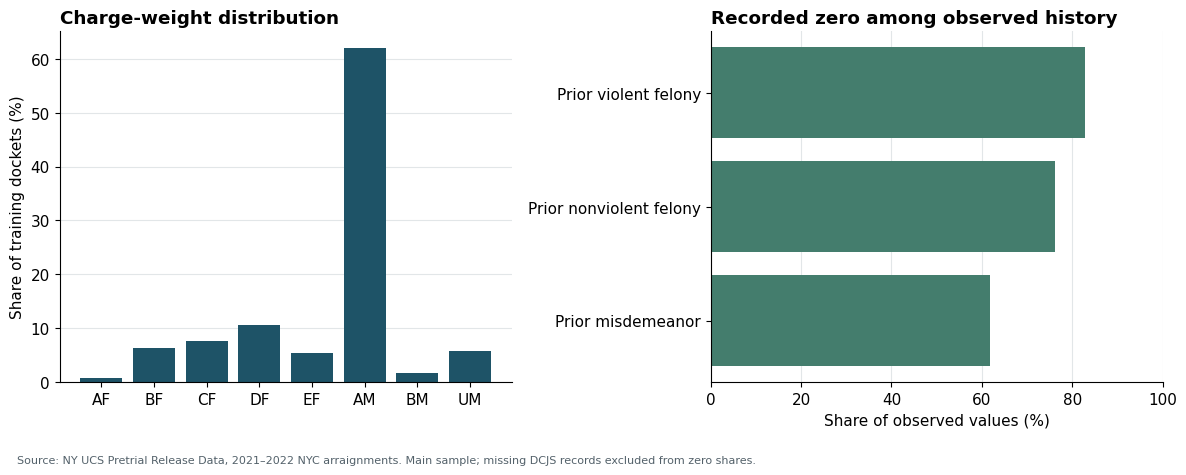

In [5]:
weights = (feature_levels.loc[feature_levels["feature"].eq("top_charge_weight_at_arraign")]
           .set_index("level")["share_pct"].reindex(config.SEVERITY_ORDER))
prior_features = ["prior_vfo_cnt", "prior_nonvfo_cnt", "prior_misd_cnt"]
zero_shares = (feature_inventory.set_index("feature")
               .loc[prior_features, "zero_pct_observed"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].bar(weights.index, weights.values, color=NAVY)
axes[0].set_title("Charge-weight distribution", loc="left", weight="bold")
axes[0].set_ylabel("Share of training dockets (%)")
axes[0].grid(axis="y", color=GRID)
axes[0].set_axisbelow(True)
labels = ["Prior violent felony", "Prior nonviolent felony", "Prior misdemeanor"]
axes[1].barh(labels, zero_shares.values, color=TEAL)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 100)
axes[1].set_title("Recorded zero among observed history", loc="left", weight="bold")
axes[1].set_xlabel("Share of observed values (%)")
axes[1].grid(axis="x", color=GRID)
axes[1].set_axisbelow(True)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.text(.02, .02, f"{SOURCE}. Main sample; missing DCJS records excluded from zero shares.",
         fontsize=8, color="#53616A")
fig.tight_layout(rect=[0, .06, 1, 1])
fig.savefig(config.FIGURES / "e01_feature_landscape.png", bbox_inches="tight")
display(fig)
plt.close(fig)

### Relationships among inputs

Charge weight and the violent-felony flag overlap strongly but are not identical. A prior violent-felony count and a pending violent-felony indicator can co-occur. The tables below use feature values only; they do not use the decision outcome. Small cross-cells are suppressed.

,top_charge_weight_at_arraign,top_charge_at_arraign_violent_felony_ind,n,weight_total,within_weight_pct
0,AF,N,853,1483,57.52
1,AF,Y,630,1483,42.48
2,AM,N,119732,119732,100.00
3,BF,N,5137,12063,42.58
4,BF,Y,6926,12063,57.42
5,BM,N,3211,3211,100.00
6,CF,N,523,14555,3.59
7,CF,Y,14032,14555,96.41
8,DF,N,8547,20432,41.83
9,DF,Y,11885,20432,58.17


,prior_vfo_any,pending_vfo_any,n,share_pct
0,False,False,144784,75.61
1,False,True,13691,7.15
2,True,False,28116,14.68
3,True,True,4891,2.55


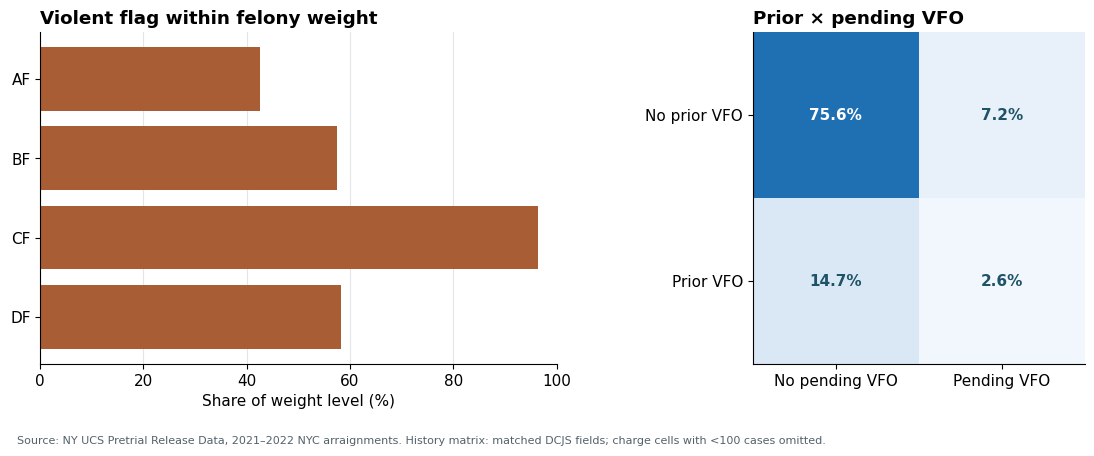

In [6]:
charge_joint = (data.groupby(["top_charge_weight_at_arraign",
                              "top_charge_at_arraign_violent_felony_ind"],
                             observed=True).size().rename("n").reset_index())
charge_joint["weight_total"] = charge_joint.groupby(
    "top_charge_weight_at_arraign")["n"].transform("sum")
charge_joint["within_weight_pct"] = charge_joint["n"] / charge_joint["weight_total"] * 100
charge_joint = charge_joint.loc[charge_joint["n"] >= config.MIN_GROUP_N].copy()
display(charge_joint.round(2))

matched = data.loc[data["prior_vfo_cnt"].notna() & data["pend_vfo"].notna()].copy()
matched["prior_vfo_any"] = pd.to_numeric(matched["prior_vfo_cnt"]).gt(0)
matched["pending_vfo_any"] = pd.to_numeric(matched["pend_vfo"]).gt(0)
history_joint = (matched.groupby(["prior_vfo_any", "pending_vfo_any"], observed=True)
                 .size().rename("n").reset_index())
history_joint["share_pct"] = history_joint["n"] / len(matched) * 100
assert history_joint["n"].ge(config.MIN_GROUP_N).all()
history_joint.to_csv(config.REPORTS / "e01_feature_joint_history.csv", index=False)
display(history_joint.round(2))

matrix = (history_joint.pivot(index="prior_vfo_any", columns="pending_vfo_any", values="share_pct")
          .reindex(index=[False, True], columns=[False, True]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
violent_by_weight = charge_joint.loc[
    charge_joint["top_charge_at_arraign_violent_felony_ind"].eq("Y")
].set_index("top_charge_weight_at_arraign")["within_weight_pct"]
felony_weights = [w for w in config.SEVERITY_ORDER
                  if w.endswith("F") and w in violent_by_weight.index]
violent_by_weight = violent_by_weight.reindex(felony_weights)
axes[0].barh(felony_weights, violent_by_weight, color=RUST)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 100)
axes[0].set_title("Violent flag within felony weight", loc="left", weight="bold")
axes[0].set_xlabel("Share of weight level (%)")
axes[0].grid(axis="x", color=GRID)
axes[0].set_axisbelow(True)
im = axes[1].imshow(matrix.values, cmap="Blues", vmin=0, vmax=100)
for row in range(len(matrix.index)):
    for col in range(len(matrix.columns)):
        axes[1].text(col, row, f"{matrix.iloc[row, col]:.1f}%", ha="center", va="center",
                     color="white" if matrix.iloc[row, col] > 45 else NAVY, weight="bold")
axes[1].set_xticks([0, 1], ["No pending VFO", "Pending VFO"])
axes[1].set_yticks([0, 1], ["No prior VFO", "Prior VFO"])
axes[1].set_title("Prior × pending VFO", loc="left", weight="bold")
fig.text(.02, .02, f"{SOURCE}. History matrix: matched DCJS fields; charge cells with <{config.MIN_GROUP_N} cases omitted.",
         fontsize=8, color="#53616A")
fig.tight_layout(rect=[0, .06, 1, 1])
fig.savefig(config.FIGURES / "e01_feature_relationships.png", bbox_inches="tight")
display(fig)
plt.close(fig)

### Stability between the two training years

For each CASE feature, total variation distance (TVD) is half the sum of absolute differences between its 2021 and 2022 level shares. It is expressed here as percentage points of distribution mass; a larger value means more distribution change, not a model-performance change. Age uses the project age bins. This check stays within the training years.

,feature,tvd_pp
6,arrest_type,5.57
4,arraign_charge_category,3.85
17,age_at_arrest,1.57
16,dat_wo_ws_prior_to_arraign,1.35
1,top_charge_weight_at_arraign,1.02
10,prior_misd_cnt,0.85
8,prior_vfo_cnt,0.68
13,pend_misd,0.38
3,top_arraign_attempt_indicator,0.38
14,supervision,0.37


,year,n,felony_pct,violent_charge_pct,dat_pct,prior_vfo_any_pct_observed,pending_vfo_pct_observed,dcjs_missing_pct,prior_dat_nonappearance_pct,median_age
0,2021,89189,30.44,17.47,17.77,16.87,9.66,0.93,4.60,33.0
1,2022,104007,30.64,17.25,12.21,17.55,9.75,0.85,3.25,33.0


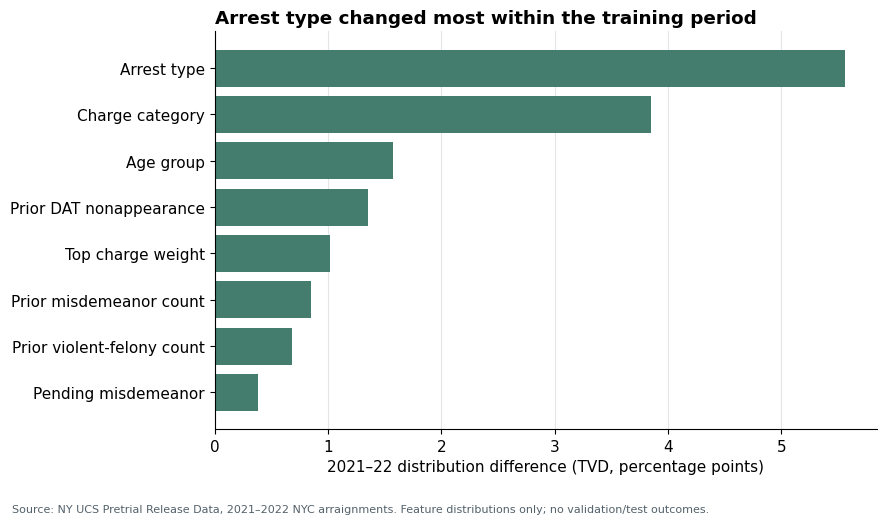

In [7]:
train_years = sorted(config.TRAIN_YEARS)
drift_rows = []
year_level_rows = []
for feature in config.FEATURES_CASE:
    if feature == "age_at_arrest":
        levels = data["age_group"].astype("string").fillna("Missing")
    elif feature in NUMERIC:
        levels = (pd.to_numeric(data[feature], errors="coerce").astype("Int64")
                  .astype("string").fillna("Missing"))
    else:
        levels = data[feature].astype("string").fillna("Missing")
    first = levels.loc[data[config.YEAR_COL].eq(train_years[0])].value_counts(normalize=True)
    second = levels.loc[data[config.YEAR_COL].eq(train_years[1])].value_counts(normalize=True)
    union = first.index.union(second.index)
    tvd = .5 * (first.reindex(union, fill_value=0) -
                second.reindex(union, fill_value=0)).abs().sum()
    drift_rows.append({"feature": feature, "tvd_pp": float(tvd * 100)})
    for year in train_years:
        year_levels = levels.loc[data[config.YEAR_COL].eq(year)].value_counts()
        n_year = int(data[config.YEAR_COL].eq(year).sum())
        for level, n in year_levels.items():
            if n >= config.MIN_GROUP_N:
                year_level_rows.append({"feature": feature, "year": year,
                                        "level": level, "n": int(n),
                                        "share_pct": float(n / n_year * 100)})
feature_year_levels = pd.DataFrame(year_level_rows)
feature_year_levels.to_csv(config.REPORTS / "e01_feature_year_levels.csv", index=False)
feature_drift = pd.DataFrame(drift_rows).sort_values("tvd_pp", ascending=False)
feature_drift.to_csv(config.REPORTS / "e01_feature_drift.csv", index=False)
display(feature_drift.round(2))

year_rows = []
for year in train_years:
    group = data.loc[data[config.YEAR_COL].eq(year)]
    prior_observed = group["prior_vfo_cnt"].notna()
    pending_observed = group["pend_vfo"].notna()
    year_rows.append({
        "year": year, "n": len(group),
        "felony_pct": float(group["top_severity_at_arraign"].eq("Felony").mean() * 100),
        "violent_charge_pct": float(group["top_charge_at_arraign_violent_felony_ind"].eq("Y").mean() * 100),
        "dat_pct": float(group["arrest_type"].eq("DAT").mean() * 100),
        "prior_vfo_any_pct_observed": float(pd.to_numeric(group.loc[prior_observed, "prior_vfo_cnt"]).gt(0).mean() * 100),
        "pending_vfo_pct_observed": float(pd.to_numeric(group.loc[pending_observed, "pend_vfo"]).gt(0).mean() * 100),
        "dcjs_missing_pct": float(group["dcjs_missing"].eq(1).mean() * 100),
        "prior_dat_nonappearance_pct": float(group["dat_wo_ws_prior_to_arraign"].eq("Y").mean() * 100),
        "median_age": float(pd.to_numeric(group["age_at_arrest"]).median()),
    })
feature_yearly = pd.DataFrame(year_rows)
feature_yearly.to_csv(config.REPORTS / "e01_feature_yearly.csv", index=False)
display(feature_yearly.round(2))

plot_drift = feature_drift.iloc[:8].sort_values("tvd_pp")
display_names = {
    "arrest_type": "Arrest type",
    "arraign_charge_category": "Charge category",
    "age_at_arrest": "Age group",
    "dat_wo_ws_prior_to_arraign": "Prior DAT nonappearance",
    "top_charge_weight_at_arraign": "Top charge weight",
    "prior_misd_cnt": "Prior misdemeanor count",
    "prior_vfo_cnt": "Prior violent-felony count",
    "pend_misd": "Pending misdemeanor",
}
fig, ax = plt.subplots(figsize=(9, 5.3))
ax.barh(plot_drift["feature"].map(display_names), plot_drift["tvd_pp"], color=TEAL)
ax.set_xlabel("2021–22 distribution difference (TVD, percentage points)")
ax.set_title("Arrest type changed most within the training period", loc="left", weight="bold")
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
fig.text(.02, .02, f"{SOURCE}. Feature distributions only; no validation/test outcomes.",
         fontsize=8, color="#53616A")
fig.tight_layout(rect=[0, .06, 1, 1])
fig.savefig(config.FIGURES / "e01_feature_drift.png", bbox_inches="tight")
display(fig)
plt.close(fig)

## 4. Decision rates across case and defendant variables

Each row reports the number of dockets, the number with bail set or remand, and the rate. Small groups are removed, and low outcome or complement counts have their rates suppressed before display. The top 12 charge categories are selected by *frequency*, not by outcome rate.

In [8]:
def rate_table(frame, by):
    # Aggregate a training-only frame without returning individual records.
    out = (frame.groupby(by, dropna=False, observed=True)[config.TARGET_Q1]
           .agg(n="size", bail_or_remand="sum").reset_index())
    out = out.loc[out["n"] >= config.MIN_GROUP_N].copy()
    small_cell = (out["bail_or_remand"].lt(config.MIN_GROUP_N) |
                  (out["n"] - out["bail_or_remand"]).lt(config.MIN_GROUP_N))
    out["rate"] = (out["bail_or_remand"] / out["n"]).mask(small_cell)
    out["bail_or_remand"] = out["bail_or_remand"].mask(small_cell).astype("Int64")
    return out


numeric_counts = ["prior_vfo_cnt", "prior_nonvfo_cnt", "prior_misd_cnt",
                  "pend_vfo", "pend_nonvfo", "pend_misd", "supervision"]
for col in numeric_counts:
    data[col + "_group"] = pd.to_numeric(data[col], errors="coerce").astype("Int64").astype("string").fillna("DCJS missing")

group_vars = [
    config.YEAR_COL, "top_severity_at_arraign", "top_charge_weight_at_arraign",
    "top_charge_at_arraign_violent_felony_ind", "arraign_charge_category",
    *[col + "_group" for col in numeric_counts],
    "dat_wo_ws_prior_to_arraign", "age_group", "gender", "arrest_type",
]
tables = {col: rate_table(data, col) for col in group_vars}
top_categories = (data["arraign_charge_category"].astype("string")
                  .fillna("Missing").value_counts().head(12).index)
tables["arraign_charge_category"] = tables["arraign_charge_category"].loc[
    tables["arraign_charge_category"]["arraign_charge_category"].isin(top_categories)
].copy()
for col, table in tables.items():
    print(f"\n{col}")
    display(table.sort_values("n", ascending=False).reset_index(drop=True))


arraign_year


,arraign_year,n,bail_or_remand,rate
0,2022,104007,13467,0.129482
1,2021,89189,11512,0.129074



top_severity_at_arraign


,top_severity_at_arraign,n,bail_or_remand,rate
0,Misdemeanor,134180,3094,0.023059
1,Felony,59016,21885,0.370832



top_charge_weight_at_arraign


,top_charge_weight_at_arraign,n,bail_or_remand,rate
0,AM,119732,3068,0.025624
1,DF,20432,5064,0.247847
2,CF,14555,8081,0.555204
3,BF,12063,5555,0.460499
4,UM,11237,<NA>,NaN
5,EF,10483,2022,0.192884
6,BM,3211,<NA>,NaN
7,AF,1483,1163,0.784221


... (22 outputs left out)


gender


,gender,n,bail_or_remand,rate
0,Male,157873,23390,0.148157
1,Female,35309,1585,0.044889



arrest_type


,arrest_type,n,bail_or_remand,rate
0,Custody,164648,24862,0.151001
1,DAT,28548,117,0.004098


### Charge severity and prior violent felony history

This cross-tab tests whether prior-record differences remain visible *within* the broad felony/misdemeanor split. A missing DCJS match is shown separately because it does not mean no prior record.

,top_severity_at_arraign,prior_vfo_status,n,bail_or_remand,rate
0,Felony,At least one prior VFO,13299,6788,0.510414
1,Felony,DCJS missing,140,<NA>,NaN
2,Felony,No recorded prior VFO,45577,15069,0.330627
3,Misdemeanor,At least one prior VFO,19708,931,0.047240
4,Misdemeanor,DCJS missing,1574,<NA>,NaN
5,Misdemeanor,No recorded prior VFO,112898,2163,0.019159


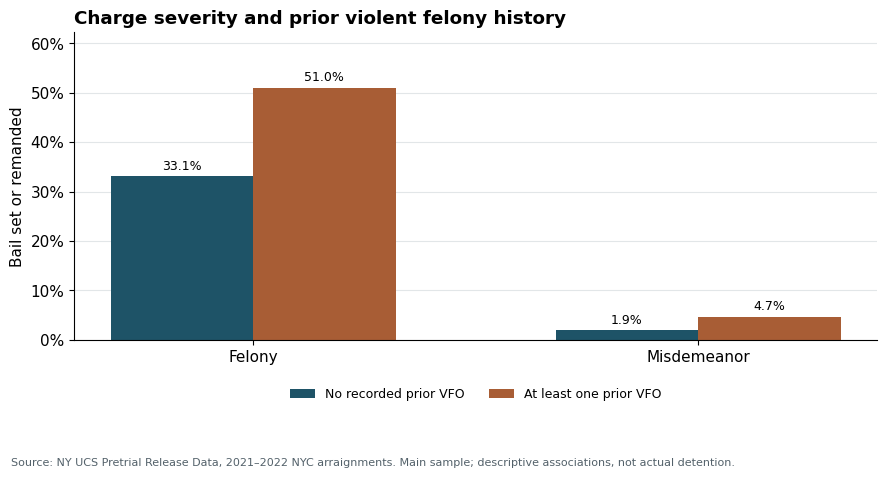

In [9]:
prior_vfo = pd.to_numeric(data["prior_vfo_cnt"], errors="coerce")
data["prior_vfo_status"] = np.select(
    [prior_vfo.isna(), prior_vfo.gt(0)],
    ["DCJS missing", "At least one prior VFO"],
    default="No recorded prior VFO",
)
severity_prior = rate_table(data, ["top_severity_at_arraign", "prior_vfo_status"])
display(severity_prior.sort_values(["top_severity_at_arraign", "prior_vfo_status"]))

fig, ax = plt.subplots(figsize=(9, 4.8))
order = ["No recorded prior VFO", "At least one prior VFO"]
severities = [s for s in ["Felony", "Misdemeanor"] if s in severity_prior["top_severity_at_arraign"].values]
x = np.arange(len(severities))
width = 0.32
for i, (status, color) in enumerate(zip(order, [NAVY, RUST])):
    values = (severity_prior.loc[severity_prior["prior_vfo_status"].eq(status)]
              .set_index("top_severity_at_arraign")["rate"].reindex(severities))
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=status, color=color)
    for bar, value in zip(bars, values):
        if pd.notna(value):
            ax.annotate(f"{value:.1%}", (bar.get_x() + bar.get_width()/2, value),
                        ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
ax.set_xticks(x, severities)
ax.set_ylim(0, severity_prior["rate"].max() * 1.22)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("Bail set or remanded")
ax.set_title("Charge severity and prior violent felony history", loc="left", weight="bold")
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(.5, -.12), fontsize=9)
fig.text(.02, .015, f"{SOURCE}. Main sample; descriptive associations, not actual detention.", fontsize=8, color="#53616A")
fig.tight_layout(rect=[0, .09, 1, 1])
fig.savefig(config.FIGURES / "e01_severity_prior_vfo.png", bbox_inches="tight")
display(fig)
plt.close(fig)

## 5. Race: raw and case-stratified descriptions

The raw table mixes case types. The second table compares recorded race within felony/misdemeanor × prior-VFO strata. These are descriptive differences; they do not establish discrimination or equal case circumstances. Unknown race and missing DCJS history are retained as explicit categories.

In [10]:
data["race_group"] = data["race"].astype("string").fillna("Unknown/missing")
race_raw = rate_table(data, "race_group").sort_values("n", ascending=False)
race_stratified = rate_table(data, ["top_severity_at_arraign", "prior_vfo_status", "race_group"])
display(race_raw)
display(race_stratified.sort_values(["top_severity_at_arraign", "prior_vfo_status", "race_group"]))

,race_group,n,bail_or_remand,rate
2,Black,111070,16818,0.151418
5,White,68183,7089,0.103970
4,Unknown,6871,521,0.075826
1,Asian/Pacific Islander,6715,514,0.076545
0,American Indian/Alaskan Native,345,<NA>,NaN


,top_severity_at_arraign,prior_vfo_status,race_group,n,bail_or_remand,rate
1,Felony,At least one prior VFO,Asian/Pacific Islander,102,<NA>,NaN
2,Felony,At least one prior VFO,Black,9710,5070,0.522142
4,Felony,At least one prior VFO,Unknown,143,<NA>,NaN
5,Felony,At least one prior VFO,White,3332,1578,0.473589
11,Felony,No recorded prior VFO,Asian/Pacific Islander,1575,381,0.241905
12,Felony,No recorded prior VFO,Black,27209,9806,0.360395
14,Felony,No recorded prior VFO,Unknown,1482,372,0.251012
15,Felony,No recorded prior VFO,White,15232,4493,0.294971
17,Misdemeanor,At least one prior VFO,Asian/Pacific Islander,123,<NA>,NaN
18,Misdemeanor,At least one prior VFO,Black,14443,693,0.047982


### Case-feature composition across audit groups

The table profiles **dockets**, not unique people. Gender and race are audit groupings, not main-model predictors. Prior-VFO percentages use only dockets with an observed DCJS prior field; a missing match is never treated as zero. The within-felony violent-charge column changes the denominator from all dockets to felony dockets, illustrating how a raw group comparison can change with case mix. This is descriptive and does not explain why any group difference exists. The A2 proxy-variable analysis in notebook 02 covers the interpretation in more detail.

In [11]:
def safe_feature_share(flag, eligible):
    n = int(eligible.sum())
    positives = int((flag & eligible).sum())
    if min(n, positives, n - positives) < config.MIN_GROUP_N:
        return np.nan
    return positives / n

composition_rows = []
for dimension, levels in [("gender", ["Male", "Female"]),
                          ("race", ["Black", "White"])]:
    for level in levels:
        group = data.loc[data[dimension].eq(level)]
        all_cases = pd.Series(True, index=group.index)
        felony = group["top_severity_at_arraign"].eq("Felony")
        violent = group["top_charge_at_arraign_violent_felony_ind"].eq("Y")
        prior_observed = group["prior_vfo_cnt"].notna()
        composition_rows.append({
            "dimension": dimension, "level": level, "n": len(group),
            "felony_share": safe_feature_share(felony, all_cases),
            "violent_charge_share_all": safe_feature_share(violent, all_cases),
            "violent_charge_share_felony": safe_feature_share(violent, felony),
            "prior_vfo_share_observed": safe_feature_share(
                pd.to_numeric(group["prior_vfo_cnt"], errors="coerce").gt(0),
                prior_observed),
        })
composition = pd.DataFrame(composition_rows)
display(composition.round(4))

,dimension,level,n,felony_share,violent_charge_share_all,violent_charge_share_felony,prior_vfo_share_observed
0,gender,Male,157873,0.3243,0.1822,0.5618,0.2022
1,gender,Female,35309,0.2211,0.1343,0.6076,0.0394
2,race,Black,111070,0.3332,0.1992,0.5979,0.2192
3,race,White,68183,0.2729,0.1410,0.5169,0.1225


## 6. Bail set but not recorded as made

The agreed descriptive proxy is a missing `bail_made_indicator` among **main-sample bail-set** dockets (nominal bail already excluded). It is an event after the decision, so this field is deliberately absent from the model feature sets. Missingness is interpreted according to the team handoff and should be checked against the UCS dictionary before making a stronger claim about actual payment.

In [12]:
bail = data.loc[data[config.RELEASE_COL].eq("Bail-set"), ["bail_made_indicator"]]
not_recorded_made = int(bail["bail_made_indicator"].isna().sum())
bail_summary = pd.DataFrame([{
    "bail_set_n": len(bail),
    "bail_made_indicator_missing_n": not_recorded_made,
    "share_missing": not_recorded_made / len(bail) if len(bail) else np.nan,
}])
assert len(bail) >= config.MIN_GROUP_N
display(bail_summary)

,bail_set_n,bail_made_indicator_missing_n,share_missing
0,23077,16433,0.712094


## 7. Finding for the analysis deck

Reuse C-01's **training-only** anonymous-judge summary. The expected rate uses pooled charge-weight × violent-charge cells, so this is a coarse case-mix adjustment. The plotted P10 and P90 are percentiles *across judges* with at least `MIN_GROUP_N` cases within the severity, not confidence intervals. Prior history and other differences are not adjusted here.

**Action implied by the finding:** compare `CASE_COURT` and `CASE_COURT_JUDGE` on the 2023 validation year using the common modeling and evaluation functions. Report how much judge coding coverage limits that comparison. The figure alone cannot show a causal judge effect.

,severity,n_judges,n,observed_minus_expected_p10,observed_minus_expected_p50,observed_minus_expected_p90
1,Felony,108,53705,-0.081922,-0.000959,0.092872
2,Misdemeanor,165,131794,-0.017343,-0.001151,0.025743


Felony judge residuals (P10–P90): -8.2% to +9.3%; compare out-of-time CASE_COURT and CASE_COURT_JUDGE models next.


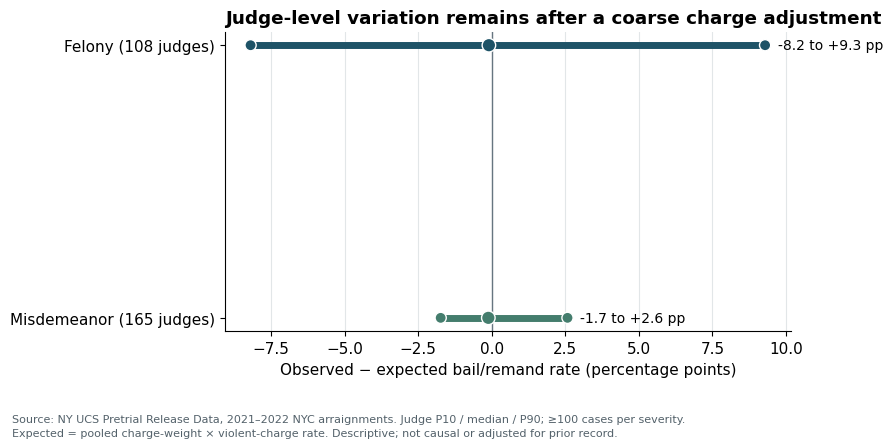

In [13]:
judge = pd.read_csv(config.REPORTS / "c01_judge_percentiles.csv")
judge = judge.loc[judge["severity"].isin(["Felony", "Misdemeanor"])].copy()
assert len(judge) == 2 and judge["n"].ge(config.MIN_GROUP_N).all()
display(judge[["severity", "n_judges", "n", "observed_minus_expected_p10",
               "observed_minus_expected_p50", "observed_minus_expected_p90"]])
felony = judge.set_index("severity").loc["Felony"]
print(
    "Felony judge residuals (P10–P90): "
    f"{felony['observed_minus_expected_p10']:+.1%} to "
    f"{felony['observed_minus_expected_p90']:+.1%}; "
    "compare out-of-time CASE_COURT and CASE_COURT_JUDGE models next."
)

fig, ax = plt.subplots(figsize=(9, 4.5))
judge = judge.set_index("severity").reindex(["Felony", "Misdemeanor"])
for i, (severity, row) in enumerate(judge.iterrows()):
    low = row["observed_minus_expected_p10"] * 100
    middle = row["observed_minus_expected_p50"] * 100
    high = row["observed_minus_expected_p90"] * 100
    ax.plot([low, high], [i, i], color=NAVY if i == 0 else TEAL, lw=5, solid_capstyle="round")
    ax.scatter([low, middle, high], [i, i, i], color=NAVY if i == 0 else TEAL,
               s=[65, 95, 65], zorder=3, edgecolor="white")
    ax.annotate(f"{low:+.1f} to {high:+.1f} pp", (high, i), xytext=(9, 0),
                textcoords="offset points", va="center", fontsize=10)
ax.axvline(0, color="#667580", lw=1)
ax.set_yticks([0, 1], [f"Felony ({judge.loc['Felony', 'n_judges']:.0f} judges)",
                        f"Misdemeanor ({judge.loc['Misdemeanor', 'n_judges']:.0f} judges)"])
ax.invert_yaxis()
ax.set_xlabel("Observed − expected bail/remand rate (percentage points)")
ax.set_title("Judge-level variation remains after a coarse charge adjustment", loc="left", weight="bold")
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
fig.text(.02, .045, f"{SOURCE}. Judge P10 / median / P90; ≥{config.MIN_GROUP_N} cases per severity.", fontsize=8, color="#53616A")
fig.text(.02, .015, "Expected = pooled charge-weight × violent-charge rate. Descriptive; not causal or adjusted for prior record.", fontsize=8, color="#53616A")
fig.tight_layout(rect=[0, .11, 1, 1])
fig.savefig(config.FIGURES / "e01_judge_discovery.png", bbox_inches="tight")
display(fig)
plt.close(fig)

## 8. Could the spread arise from many judge codes and uneven caseloads?

This training-only permutation check keeps the same 108 eligible felony judges, their case assignments, caseloads, and observed charge mix. It shuffles the bail/remand outcome among cases in the same strata and recalculates the P90–P10 residual spread. The first baseline uses charge weight × violent-charge status; the second also keeps county and arraignment year. The latter lets county/year differences contribute to the simulated spread, making it a more conservative check of this chart's coarse adjustment.

The simulated spreads quantify variation expected under **exchangeability within the stated strata**. A larger observed spread argues against the number of judge codes and sampling noise alone. It cannot separate a judge effect from unmeasured case differences, nonrandom assignment, or data quality problems. This is an exploratory diagnostic, not a causal test or a basis for ranking judges.

,scenario,median_pp,p95_pp
0,Charge strata,5.71,6.68
1,County × year × charge strata,9.27,10.19
2,Observed,17.48,NaN


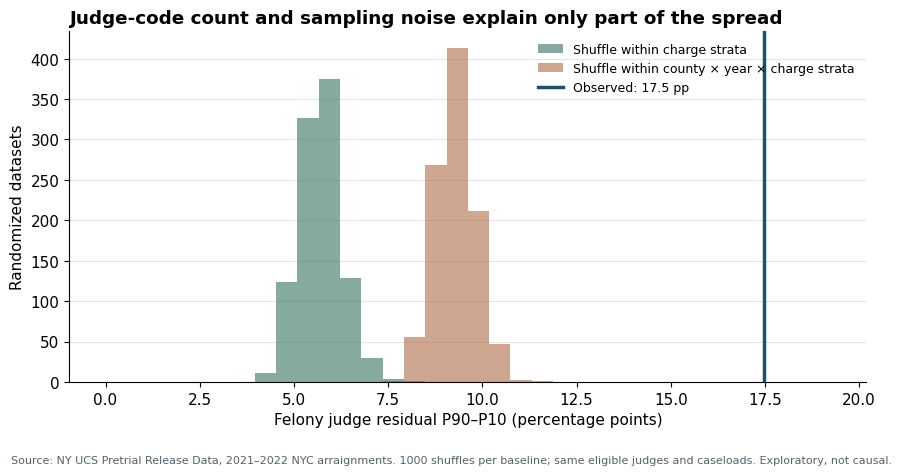

In [14]:
grid = ["top_charge_weight_at_arraign", "top_charge_at_arraign_violent_felony_ind"]
diagnostic = data[[config.YEAR_COL, config.TARGET_Q1, "judge_id", "county_name",
                   "top_severity_at_arraign", *grid]].copy()
diagnostic[grid] = diagnostic[grid].astype("string").fillna("Missing")
diagnostic["expected"] = diagnostic.groupby(grid, observed=True)[config.TARGET_Q1].transform("mean")
felony_cases = diagnostic.loc[diagnostic["top_severity_at_arraign"].eq("Felony")].reset_index(drop=True)
eligible_ids = pd.read_csv(config.REPORTS / "c01_judge_rates.csv").loc[
    lambda x: x["severity"].eq("Felony"), "judge_id"
].tolist()
judge_code = pd.Index(eligible_ids).get_indexer(felony_cases["judge_id"].astype(str))
eligible_case = judge_code >= 0
caseload = np.bincount(judge_code[eligible_case], minlength=len(eligible_ids))
assert len(eligible_ids) == int(judge.loc["Felony", "n_judges"])
assert caseload.min() >= config.MIN_GROUP_N
expected_by_judge = (
    np.bincount(judge_code[eligible_case],
                weights=felony_cases.loc[eligible_case, "expected"],
                minlength=len(eligible_ids)) / caseload
)
outcomes = felony_cases[config.TARGET_Q1].to_numpy(dtype=np.int8)

def residual_spread(labels):
    rates = np.bincount(judge_code[eligible_case], weights=labels[eligible_case],
                        minlength=len(eligible_ids)) / caseload
    residuals = rates - expected_by_judge
    return np.quantile(residuals, .9) - np.quantile(residuals, .1)

observed_spread = residual_spread(outcomes)
published_spread = (judge.loc["Felony", "observed_minus_expected_p90"]
                    - judge.loc["Felony", "observed_minus_expected_p10"])
assert np.isclose(observed_spread, published_spread)

def permutation_spreads(strata):
    groups = [np.asarray(indices, dtype=np.int64) for indices in
              felony_cases.groupby(strata, dropna=False, observed=True).indices.values()]
    rng = np.random.default_rng(config.RANDOM_STATE)
    draws = np.empty(config.N_BOOTSTRAP)
    for repeat in range(config.N_BOOTSTRAP):
        shuffled = outcomes.copy()
        for indices in groups:
            shuffled[indices] = outcomes[indices][rng.permutation(len(indices))]
        draws[repeat] = residual_spread(shuffled)
    return draws

null_charge = permutation_spreads(grid)
null_county_year_charge = permutation_spreads(["county_name", config.YEAR_COL, *grid])
null_summary = pd.DataFrame([
    {"scenario": "Charge strata", "median_pp": np.median(null_charge)*100,
     "p95_pp": np.quantile(null_charge, .95)*100},
    {"scenario": "County × year × charge strata", "median_pp": np.median(null_county_year_charge)*100,
     "p95_pp": np.quantile(null_county_year_charge, .95)*100},
    {"scenario": "Observed", "median_pp": observed_spread*100, "p95_pp": np.nan},
])
display(null_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 4.8))
bins = np.linspace(0, observed_spread * 110, 35)
ax.hist(null_charge * 100, bins=bins, color=TEAL, alpha=.65, label="Shuffle within charge strata")
ax.hist(null_county_year_charge * 100, bins=bins, color=RUST, alpha=.55,
        label="Shuffle within county × year × charge strata")
ax.axvline(observed_spread * 100, color=NAVY, lw=2.5,
           label=f"Observed: {observed_spread*100:.1f} pp")
ax.set_xlabel("Felony judge residual P90–P10 (percentage points)")
ax.set_ylabel("Randomized datasets")
ax.set_title("Judge-code count and sampling noise explain only part of the spread",
             loc="left", weight="bold")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
fig.text(.02, .02,
         f"{SOURCE}. {config.N_BOOTSTRAP} shuffles per baseline; same eligible judges and caseloads. Exploratory, not causal.",
         fontsize=8, color="#53616A")
fig.tight_layout(rect=[0, .06, 1, 1])
fig.savefig(config.FIGURES / "e01_judge_null.png", bbox_inches="tight")
display(fig)
plt.close(fig)

## 9. Interpretation checklist

- Quote the outcome as **bail set or remanded**, never as actual detention.
- Keep the descriptive race tables separate from fairness metrics on model predictions.
- Judge residuals are adjusted for charge weight and violent-charge indicator only; do not describe cases as identical or infer a judge effect.
- Use 2023 validation predictions to evaluate the proposed judge-feature comparison. The 2024 test remains sealed until the project freeze.